In [14]:
import pandas as pd

df = pd.read_csv("customer_churn.csv")

print("Rows and columns:", df.shape)
display(df.drop(columns=["Names", "Location", "Company"]).head())
print(df.columns.tolist())

Rows and columns: (900, 10)


,Age,Total_Purchase,Account_Manager,Years,Num_Sites,Onboard_date,Churn
0,42.0,11066.80,0,7.22,8.0,2013-08-30 07:00:40,1
1,41.0,11916.22,0,6.50,11.0,2013-08-13 00:38:46,1
2,38.0,12884.75,0,6.67,12.0,2016-06-29 06:20:07,1
3,42.0,8010.76,0,6.71,10.0,2014-04-22 12:43:12,1
4,37.0,9191.58,0,5.56,9.0,2016-01-19 15:31:15,1


['Names', 'Age', 'Total_Purchase', 'Account_Manager', 'Years', 'Num_Sites', 'Onboard_date', 'Location', 'Company', 'Churn']


In [2]:
counts = df["Churn"].value_counts().sort_index()
percentages = df["Churn"].value_counts(normalize=True).sort_index() * 100

display(pd.DataFrame({
    "Customers": counts,
    "Percent": percentages.round(1)
}))

,Customers,Percent
Churn,,
0,750,83.3
1,150,16.7


In [3]:
display(pd.DataFrame({
    "Data type": df.dtypes,
    "Missing values": df.isna().sum()
}))

print("Duplicate rows:", df.duplicated().sum())

,Data type,Missing values
Names,object,0
Age,float64,0
Total_Purchase,float64,0
Account_Manager,int64,0
Years,float64,0
Num_Sites,float64,0
Onboard_date,object,0
Location,object,0
Company,object,0
Churn,int64,0


Duplicate rows: 0


In [4]:
tenure_summary = (
    df.groupby("Churn")["Years"]
    .agg(["count", "mean", "median"])
    .round(2)
)

display(tenure_summary)

,count,mean,median
Churn,,,
0,750,5.15,5.08
1,150,5.88,5.80


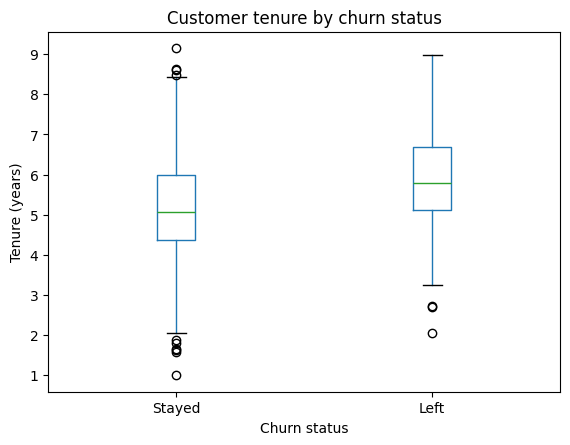

In [5]:
import matplotlib.pyplot as plt

ax = df.boxplot(column="Years", by="Churn", grid=False)
ax.set_title("Customer tenure by churn status")
ax.set_xlabel("Churn status")
ax.set_ylabel("Tenure (years)")
ax.set_xticks([1, 2], ["Stayed", "Left"])
ax.figure.suptitle("")
plt.show()

In [7]:
from sklearn.model_selection import train_test_split

features = ["Age", "Total_Purchase", "Account_Manager", "Years", "Num_Sites"]
X = df[features]
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training customers:", len(X_train))
print("Test customers:", len(X_test))
print(y_test.value_counts().sort_index())

Training customers: 720
Test customers: 180
Churn
0    150
1     30
Name: count, dtype: int64


In [8]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training means after scaling:")
print(X_train_scaled.mean(axis=0).round(3))

print("Training standard deviations after scaling:")
print(X_train_scaled.std(axis=0).round(3))

Training means after scaling:
[-0.  0.  0.  0.  0.]
Training standard deviations after scaling:
[1. 1. 1. 1. 1.]


In [9]:
import numpy as np

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

scores = np.array([-2, 0, 2])
print(sigmoid(scores).round(3))

[0.119 0.5   0.881]


In [10]:
y_train_array = y_train.to_numpy()
n_customers, n_features = X_train_scaled.shape

weights = np.zeros(n_features)
intercept = 0.0
learning_rate = 0.1

for _ in range(1000):
    scores = X_train_scaled @ weights + intercept
    probabilities = sigmoid(scores)
    errors = probabilities - y_train_array

    weight_gradient = X_train_scaled.T @ errors / n_customers
    intercept_gradient = errors.mean()

    weights -= learning_rate * weight_gradient
    intercept -= learning_rate * intercept_gradient

display(pd.Series(weights, index=features, name="Learned weight").round(3))

Age                0.307
Total_Purchase     0.051
Account_Manager    0.250
Years              0.779
Num_Sites          1.938
Name: Learned weight, dtype: float64

In [11]:
from sklearn.metrics import accuracy_score, recall_score, confusion_matrix

test_scores = X_test_scaled @ weights + intercept
test_probabilities = sigmoid(test_scores)
test_predictions = (test_probabilities >= 0.5).astype(int)

print(f"Test accuracy: {accuracy_score(y_test, test_predictions):.1%}")
print(f"Churn recall: {recall_score(y_test, test_predictions):.1%}")

display(pd.DataFrame(
    confusion_matrix(y_test, test_predictions, labels=[0, 1]),
    index=["Actually stayed", "Actually left"],
    columns=["Predicted stayed", "Predicted left"]
))

Test accuracy: 90.6%
Churn recall: 56.7%


,Predicted stayed,Predicted left
Actually stayed,146,4
Actually left,13,17


In [12]:
from sklearn.linear_model import LogisticRegression

sklearn_model = LogisticRegression(max_iter=1000)
sklearn_model.fit(X_train_scaled, y_train)

sklearn_probabilities = sklearn_model.predict_proba(X_test_scaled)[:, 1]
sklearn_predictions = (sklearn_probabilities >= 0.5).astype(int)

print(f"Test accuracy: {accuracy_score(y_test, sklearn_predictions):.1%}")
print(f"Churn recall: {recall_score(y_test, sklearn_predictions):.1%}")

print("Customers flagged differently:",
      np.sum(test_predictions != sklearn_predictions))

Test accuracy: 90.6%
Churn recall: 56.7%
Customers flagged differently: 0


In [13]:
new_customers = pd.read_csv("new_customers_1.csv")

new_scaled = scaler.transform(new_customers[features])
new_scores = new_scaled @ weights + intercept
new_probabilities = sigmoid(new_scores)

results = new_customers[features].copy()
results["Churn probability"] = (new_probabilities * 100).round(1)
results["Flagged"] = new_probabilities >= 0.5

display(results.sort_values("Churn probability", ascending=False))

,Age,Total_Purchase,Account_Manager,Years,Num_Sites,Churn probability,Flagged
1,23.0,7526.94,1,9.28,15.0,99.8,True
3,32.0,6487.50,0,9.40,14.0,99.3,True
2,65.0,100.00,1,1.00,15.0,94.8,True
5,22.0,8445.26,1,3.46,14.0,79.4,True
4,32.0,13147.71,1,10.00,8.0,35.2,False
0,37.0,9935.53,1,7.71,8.0,13.9,False


## Conclusion

I built a customer churn model using NumPy and gradient descent.
On 180 held-out customers, it achieved 90.6% accuracy, compared
with 83.3% for a baseline that predicted every customer would stay.

At the 50% cutoff, the model caught 17 of the 30 customers who left
(56.7% churn recall) and incorrectly flagged 4 customers who stayed.
Scikit-learn's logistic regression produced the same 180 predicted
labels at that cutoff.

I then applied my model to six new customers and flagged four for
follow-up. These flags are predictions. Evaluating them requires
knowing which of those customers actually leave.